# 1. Оцінювання параметрів (ОМВ та ОММ)

Дано кратну вибірку $(\xi_1, ..., \xi_n)$ і наступні розподіли

1. Exp($\lambda$ + 1 / $\lambda$)
2. N(0, $\frac{1}{\sigma^2}$)
3. $U[0, \frac{1}{\theta}]$
4. $B(n^2, 0.1)$
5. $\Gamma(\alpha^2, 5)$
6. $\beta(0.65, \frac{1}{\theta})$
7. $p * Exp(5) + (1 - p) * Exp(10)$
8. $Geom(e^{-p})$

Для одного з розподілів (відповідно до варіанта) будудуйте оцінку параметра:
- Методом моментів (ОММ)
- Методом максимальної вірогідності (ОМВ)
- Третю оцінку, яка є лінійною комбінацією 2х оцінок (0.5 ОМВ + 0.5 ОММ)

Чи будуть ці оцінки незміщені? (Можна показати моделюванням, якщо не виходить на листочку)  
Чи будуть вони консистентні? (Можна показати моделюванням, якщо не виходить на листочку)  
Дисперсія якої з оцінок буде найменшою (ОММ, ОМВ чи третя)? (теоретично або моделюванням)  

## Зауваження. Якщо не виходить знайти рішення рівняння аналітичним шляхом, використайте scipy.optimize

## Вимоги
напишіть звіт:  
1. Дайте відповіді на питання
2. Зробить вистновки які з оцінок "кращі"

## Варіант 3: $\xi \sim U\left[0, \frac{1}{\theta}\right]$, $\theta > 0$

Щільність: $f(x;\theta) = \theta,\ 0 \le x \le \frac{1}{\theta}$.

### Метод моментів (ОММ)
$E\xi = \frac{1}{2\theta}$. Прирівнюємо до вибіркового середнього: $\bar X = \frac{1}{2\theta}$ $\Rightarrow$

$$\hat\theta_{MM} = \frac{1}{2\bar X}$$

### Метод максимальної вірогідності (ОМВ)
$$L(\theta) = \prod_{i=1}^n \theta\,\mathbb 1\{0 \le \xi_i \le 1/\theta\} = \theta^n\,\mathbb 1\left\{\theta \le \frac{1}{\xi_{(n)}}\right\}$$
$L$ зростає по $\theta$ на допустимій множині $(0, 1/\xi_{(n)}]$, тому максимум на її правій межі (рівняння $\partial \ln L / \partial\theta = 0$ розв'язку не має — максимум крайовий):

$$\hat\theta_{ML} = \frac{1}{\xi_{(n)}} = \frac{1}{\max_i \xi_i}$$

### Третя оцінка
$$\hat\theta_{3} = 0.5\,\hat\theta_{ML} + 0.5\,\hat\theta_{MM}$$

### Теоретичний аналіз
**ОМВ.** $M = \xi_{(n)}$ має щільність $f_M(m) = n\theta^n m^{n-1}$, $0\le m\le 1/\theta$. Тоді
$$E\frac{1}{M} = \frac{n}{n-1}\theta,\qquad E\frac{1}{M^2} = \frac{n}{n-2}\theta^2,\qquad D\hat\theta_{ML} = \frac{n\,\theta^2}{(n-2)(n-1)^2} \sim \frac{\theta^2}{n^2}.$$
Отже ОМВ **зміщена** (зсув $\frac{\theta}{n-1}$), але **асимптотично незміщена**; оскільки зсув і дисперсія $\to 0$, вона **консистентна**. Незміщений варіант: $\frac{n-1}{n}\cdot\frac{1}{\xi_{(n)}}$.

**ОММ.** $g(x) = \frac{1}{2x}$ строго опукла, тому за нерівністю Єнсена $E\hat\theta_{MM} > \frac{1}{2E\bar X} = \theta$ — оцінка **зміщена** (вгору). За дельта-методом ($D\bar X = \frac{1}{12\theta^2 n}$, $g'(\mu) = -2\theta^2$, $g''(\mu) = 8\theta^3$):
$$E\hat\theta_{MM} - \theta \approx \frac{\theta}{3n},\qquad D\hat\theta_{MM} \approx \frac{\theta^2}{3n}.$$
За ЗВЧ $\bar X \to \frac{1}{2\theta}$ м.н., а $g$ неперервна — оцінка **консистентна**.

**Третя оцінка** — зміщена (сума двох додатних зсувів), консистентна (лінійна комбінація консистентних). $D\hat\theta_3 \approx \frac14 D\hat\theta_{MM} \approx \frac{\theta^2}{12n}$ (внесок ОМВ має порядок $1/n^2$).

**Порівняння дисперсій:** $D\hat\theta_{ML} = O(1/n^2)$ $\ll$ $D\hat\theta_{3} = O(1/n)$ $<$ $D\hat\theta_{MM} = O(1/n)$.

Нижче все перевіряємо моделюванням.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize

rng = np.random.default_rng(42)
THETA = 2.0          
M = 5000            
NS = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]

def est_mm(x, axis=-1):
    return 1 / (2 * x.mean(axis=axis))

def est_ml(x, axis=-1):
    return 1 / x.max(axis=axis)

def est_3(x, axis=-1):
    return 0.5 * est_ml(x, axis) + 0.5 * est_mm(x, axis)

ESTIMATORS = {'ОММ': est_mm, 'ОМВ': est_ml, '0.5 ОМВ + 0.5 ОММ': est_3}

### Перевірка ОМВ через `scipy.optimize`
Максимізуємо логарифм вірогідності чисельно і порівнюємо з аналітичною формулою $1/\xi_{(n)}$.

scipy.optimize:  theta_ML = 2.049974
аналітично 1/max: theta_ML = 2.049974


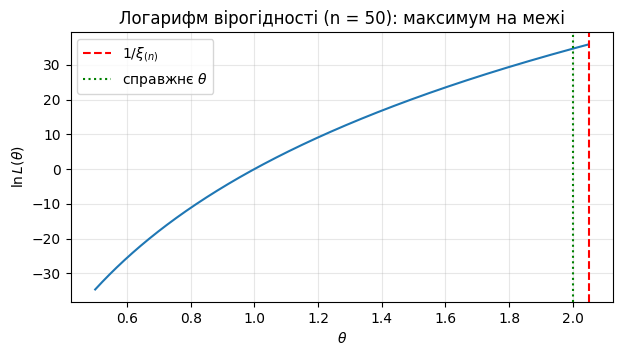

In [2]:
x = rng.uniform(0, 1 / THETA, size=50)

def neg_loglik(t):
    if t <= 0 or x.max() > 1 / t:
        return np.inf
    return -len(x) * np.log(t)

res = optimize.minimize_scalar(neg_loglik, bounds=(1e-6, 1 / x.max()), method='bounded',
                               options={'xatol': 1e-10})
print(f'scipy.optimize:  theta_ML = {res.x:.6f}')
print(f'аналітично 1/max: theta_ML = {1 / x.max():.6f}')

t = np.linspace(0.5, 3, 1000)
ll = np.array([-neg_loglik(ti) for ti in t])
plt.figure(figsize=(7, 3.5))
plt.plot(t, np.where(np.isfinite(ll), ll, np.nan))
plt.axvline(1 / x.max(), color='r', ls='--', label=r'$1/\xi_{(n)}$')
plt.axvline(THETA, color='g', ls=':', label=r'справжнє $\theta$')
plt.xlabel(r'$\theta$'); plt.ylabel(r'$\ln L(\theta)$')
plt.title('Логарифм вірогідності (n = 50): максимум на межі')
plt.legend(); plt.grid(alpha=.3); plt.show()

### Моделювання: зсув, дисперсія, MSE для різних n

In [3]:
rows = []
samples = {}
for n in NS:
    X = rng.uniform(0, 1 / THETA, size=(M, n))
    for name, f in ESTIMATORS.items():
        e = f(X)
        samples[(name, n)] = e
        rows.append((n, name, e.mean(), e.mean() - THETA, e.var(), ((e - THETA) ** 2).mean()))

print(f"{'n':>5} | {'оцінка':<18} | {'E[θ̂]':>8} | {'зсув':>9} | {'дисперсія':>10} | {'MSE':>10}")
print('-' * 76)
for n, name, m, b, v, mse in rows:
    print(f'{n:>5} | {name:<18} | {m:8.4f} | {b:9.5f} | {v:10.6f} | {mse:10.6f}')
    if name == '0.5 ОМВ + 0.5 ОММ': print('-' * 76)

    n | оцінка             |    E[θ̂] |      зсув |  дисперсія |        MSE
----------------------------------------------------------------------------
    5 | ОММ                |   2.1681 |   0.16814 |   0.545205 |   0.573477
    5 | ОМВ                |   2.4937 |   0.49367 |   0.399469 |   0.643179
    5 | 0.5 ОМВ + 0.5 ОММ  |   2.3309 |   0.33091 |   0.411858 |   0.521357
----------------------------------------------------------------------------
   10 | ОММ                |   2.0693 |   0.06931 |   0.184075 |   0.188879
   10 | ОМВ                |   2.2237 |   0.22374 |   0.062169 |   0.112228
   10 | 0.5 ОМВ + 0.5 ОММ  |   2.1465 |   0.14652 |   0.091399 |   0.112868
----------------------------------------------------------------------------
   20 | ОММ                |   2.0343 |   0.03428 |   0.076354 |   0.077529
   20 | ОМВ                |   2.1042 |   0.10422 |   0.012509 |   0.023372
   20 | 0.5 ОМВ + 0.5 ОММ  |   2.0693 |   0.06925 |   0.028073 |   0.032869
---------

Порівняння з теоретичними формулами:

In [4]:
print(f"{'n':>5} | {'зсув ОМВ':>9} {'теор.':>9} | {'D ОМВ':>10} {'теор.':>10} | {'зсув ОММ':>9} {'≈теор.':>9} | {'D ОММ':>9} {'≈теор.':>9}")
for n in NS[1:]:
    ml, mm = samples[('ОМВ', n)], samples[('ОММ', n)]
    print(f'{n:>5} | {ml.mean() - THETA:9.5f} {THETA / (n - 1):9.5f} | '
          f'{ml.var():10.7f} {n * THETA**2 / ((n - 2) * (n - 1) ** 2):10.7f} | '
          f'{mm.mean() - THETA:9.5f} {THETA / (3 * n):9.5f} | '
          f'{mm.var():9.6f} {THETA**2 / (3 * n):9.6f}')

    n |  зсув ОМВ     теор. |      D ОМВ      теор. |  зсув ОММ    ≈теор. |     D ОММ    ≈теор.
   10 |   0.22374   0.22222 |  0.0621687  0.0617284 |   0.06931   0.06667 |  0.184075  0.133333
   20 |   0.10422   0.10526 |  0.0125094  0.0123115 |   0.03428   0.03333 |  0.076354  0.066667
   50 |   0.04042   0.04082 |  0.0016596  0.0017354 |   0.01718   0.01333 |  0.028997  0.026667
  100 |   0.01996   0.02020 |  0.0004048  0.0004165 |   0.00570   0.00667 |  0.013214  0.013333
  200 |   0.00999   0.01005 |  0.0001010  0.0001020 |   0.00376   0.00333 |  0.006571  0.006667
  500 |   0.00399   0.00401 |  0.0000165  0.0000161 |   0.00164   0.00133 |  0.002638  0.002667
 1000 |   0.00201   0.00200 |  0.0000041  0.0000040 |   0.00090   0.00067 |  0.001342  0.001333
 2000 |   0.00099   0.00100 |  0.0000010  0.0000010 |  -0.00020   0.00033 |  0.000679  0.000667


Формули для ОМВ точні при будь-якому $n$, і моделювання з ними збігається. Формули для ОММ отримано дельта-методом, тому вони лише асимптотичні: при малих $n$ ($n = 10, 20$) реальна дисперсія помітно більша за $\frac{\theta^2}{3n}$, а починаючи з $n \approx 100$ моделювання й теорія збігаються. Невеликі розбіжності у зсуві ОММ при великих $n$ (зокрема від'ємний зсув при $n = 2000$) — це похибка Монте-Карло: стандартна похибка середнього $\approx \sqrt{D\hat\theta_{MM}/M}$ тут більша за сам теоретичний зсув.

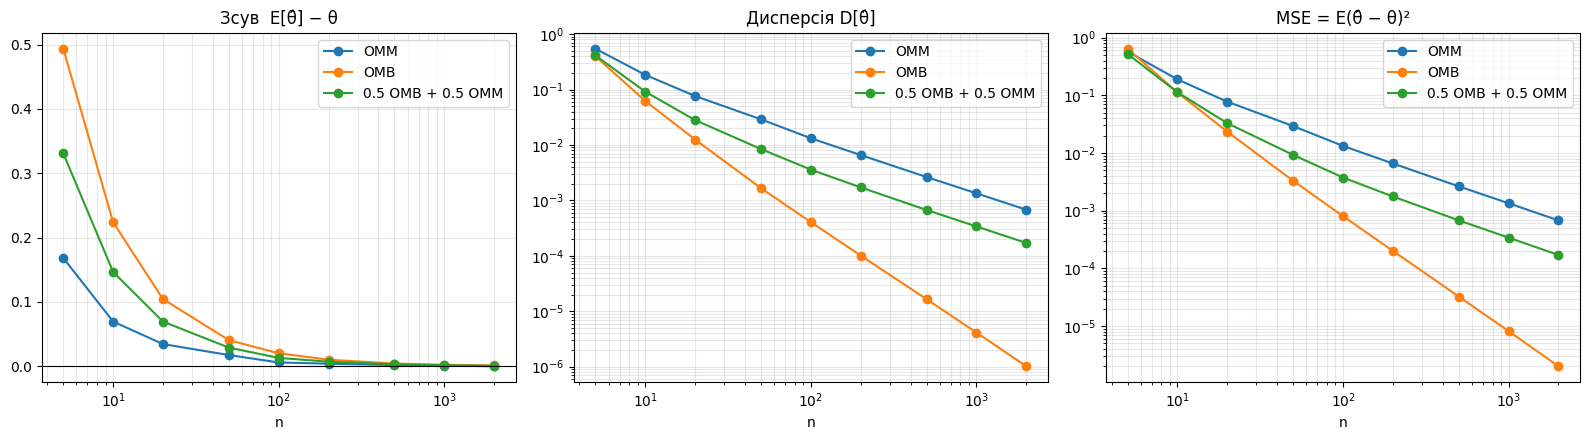

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for name in ESTIMATORS:
    b = [samples[(name, n)].mean() - THETA for n in NS]
    v = [samples[(name, n)].var() for n in NS]
    mse = [((samples[(name, n)] - THETA) ** 2).mean() for n in NS]
    axes[0].plot(NS, b, 'o-', label=name)
    axes[1].loglog(NS, v, 'o-', label=name)
    axes[2].loglog(NS, mse, 'o-', label=name)
axes[0].axhline(0, color='k', lw=.8)
axes[0].set_xscale('log')
for ax, title in zip(axes, ['Зсув  E[θ̂] − θ', 'Дисперсія D[θ̂]', 'MSE = E(θ̂ − θ)²']):
    ax.set_title(title); ax.set_xlabel('n'); ax.grid(alpha=.3, which='both'); ax.legend()
plt.tight_layout(); plt.show()

### Консистентність
Оцінюємо $P(|\hat\theta - \theta| > \varepsilon)$ для $\varepsilon = 0.1$: для консистентної оцінки ця ймовірність має прямувати до 0. Також — гістограми оцінок, що «стискаються» до $\theta$ при зростанні $n$.

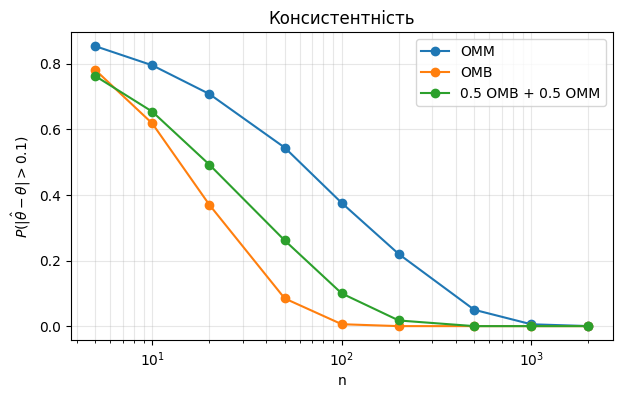

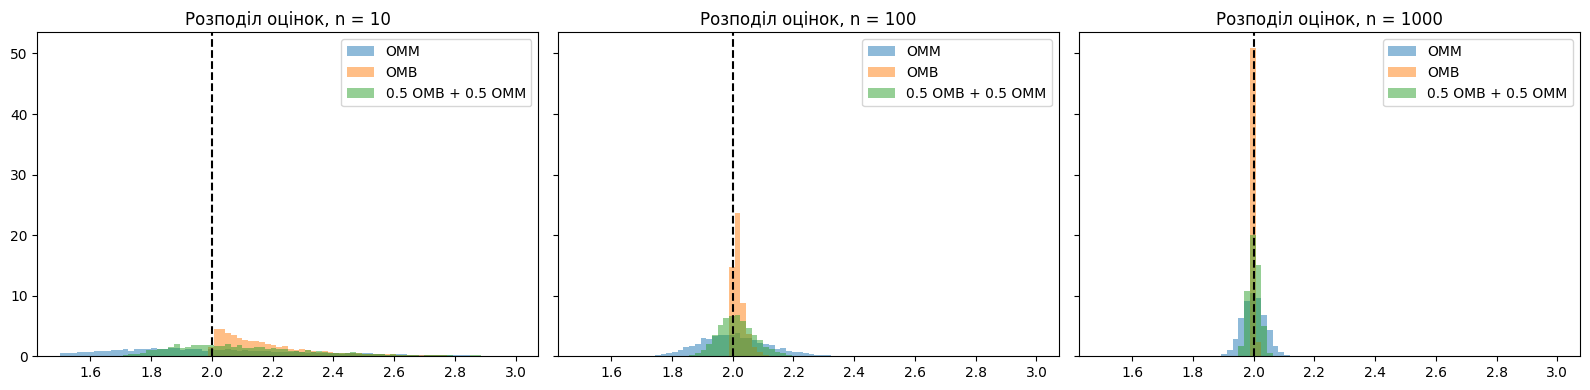

In [6]:
eps = 0.1
plt.figure(figsize=(7, 4))
for name in ESTIMATORS:
    p = [np.mean(np.abs(samples[(name, n)] - THETA) > eps) for n in NS]
    plt.semilogx(NS, p, 'o-', label=name)
plt.xlabel('n'); plt.ylabel(r'$P(|\hat\theta-\theta|>0.1)$')
plt.title('Консистентність'); plt.grid(alpha=.3, which='both'); plt.legend(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, n in zip(axes, [10, 100, 1000]):
    for name in ESTIMATORS:
        ax.hist(samples[(name, n)], bins=80, range=(1.5, 3.0), alpha=.5, density=True, label=name)
    ax.axvline(THETA, color='k', ls='--')
    ax.set_title(f'Розподіл оцінок, n = {n}'); ax.legend()
plt.tight_layout(); plt.show()

### Траєкторія оцінок на одній вибірці, що зростає

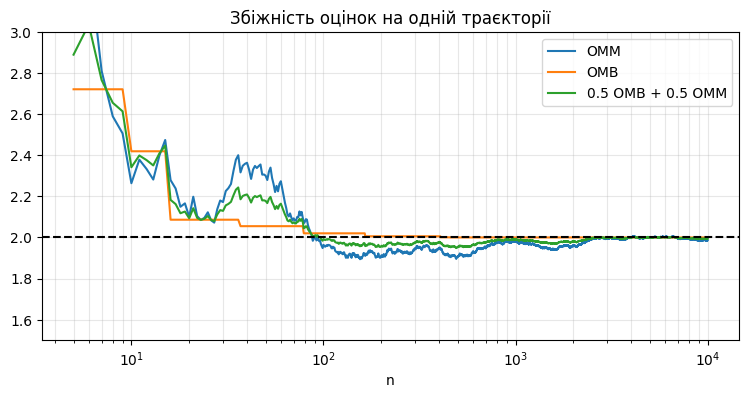

In [7]:
big = rng.uniform(0, 1 / THETA, size=10000)
ks = np.arange(5, len(big) + 1)
traj_mm = 1 / (2 * np.cumsum(big)[ks - 1] / ks)
traj_ml = 1 / np.maximum.accumulate(big)[ks - 1]
plt.figure(figsize=(9, 4))
plt.semilogx(ks, traj_mm, label='ОММ')
plt.semilogx(ks, traj_ml, label='ОМВ')
plt.semilogx(ks, 0.5 * traj_mm + 0.5 * traj_ml, label='0.5 ОМВ + 0.5 ОММ')
plt.axhline(THETA, color='k', ls='--')
plt.ylim(1.5, 3); plt.xlabel('n'); plt.title('Збіжність оцінок на одній траєкторії')
plt.grid(alpha=.3, which='both'); plt.legend(); plt.show()

### Відповіді на питання

**1. Чи незміщені оцінки?** Ні, жодна з трьох.
- ОМВ $1/\xi_{(n)}$: $E\hat\theta_{ML} = \frac{n}{n-1}\theta$ — зсув $\frac{\theta}{n-1}$ (точно, моделювання це підтверджує). Виправлена оцінка $\frac{n-1}{n\,\xi_{(n)}}$ — незміщена.
- ОММ $\frac{1}{2\bar X}$: зміщена вгору (нерівність Єнсена), зсув $\approx\frac{\theta}{3n}$.
- Третя: зміщена, зсув $\approx \frac12\left(\frac{\theta}{n-1} + \frac{\theta}{3n}\right)$.

Усі три **асимптотично незміщені** (зсув $\to 0$ на графіку).

**2. Чи консистентні?** Так, усі три: $P(|\hat\theta-\theta|>\varepsilon)\to 0$, MSE $\to 0$, траєкторії сходяться до $\theta$.

**3. Дисперсія якої оцінки найменша?** ОМВ: $D\hat\theta_{ML}\sim\theta^2/n^2$ (на log-log графіку нахил −2), тоді як у ОММ і третьої оцінки $D\sim c/n$ (нахил −1). Порядок: $D_{ML} < D_{3} < D_{MM}$ (для $n \ge 5$ вже видно в таблиці). За MSE картина при малих $n$ інша: при $n=5$ найкраща третя оцінка, а ОМВ — найгірша через великий зсув $\frac{\theta}{n-1}$; при $n=10$ MSE третьої оцінки й ОМВ майже рівні, а вже з $n \approx 20$ ОМВ однозначно краща.

### Висновок: які оцінки «кращі»
- **ОМВ** — найкраща: дисперсія і MSE на порядок менші і спадають як $1/n^2$ (це «надефективна» оцінка — нерівність Рао–Крамера тут не діє, бо носій залежить від $\theta$). Її зсув невеликий і легко усувається множником $\frac{n-1}{n}$.
- **Третя оцінка** краща за ОММ (дисперсія приблизно в 4 рази менша), але гірша за ОМВ: домішування ОММ лише «псує» ОМВ, додаючи доданок порядку $1/n$.
- **ОММ** — найгірша з трьох: використовує середнє замість достатньої статистики $\xi_{(n)}$, тому втрачає інформацію.

# 2. Застосування

Вам дано вибірку X. За її допомогою, оцініть параметри розподілу вибірки, у припущенні, що розподіл - той, що і у вашому варіанті. 

1. Побудуйте емпіричну функцію розподілу
2. Побудуйте теоретичний розподіл на основі оцінених параметрів (відповідно до варіанту)
3. Чи відповідає оцінений розподіл розподілу вибірки?
4. Напишіть висновок

In [8]:
X = np.array([ 0.06704377, -1.18488209,  0.56093463,  2.28920627, -0.52843351,
        1.64094723, -2.41745054,  0.63898792,  1.694176  ,  0.22749164,
       -0.69864633, -0.16385323,  1.41229225,  1.77067654, -1.32968981,
        0.25585254,  1.09594198,  0.80643983,  0.73262927,  0.97645904])

### Оцінювання параметрів для вибірки X (варіант 3: $U[0, 1/\theta]$)

Спершу перевіримо, чи вибірка взагалі сумісна з моделлю: носій $U[0,1/\theta]$ — відрізок $[0, 1/\theta]$, тож усі спостереження мають бути невід’ємними.

In [9]:
n = len(X)
print(f'n = {n},  mean = {X.mean():.4f},  min = {X.min():.4f},  max = {X.max():.4f}')
print(f'Від’ємних значень у вибірці: {np.sum(X < 0)} з {n}')

n = 20,  mean = 0.3923,  min = -2.4175,  max = 2.2892
Від’ємних значень у вибірці: 6 з 20


**ОМВ не існує.** Вірогідність
$$L(\theta) = \theta^n \prod_{i=1}^n \mathbb 1\{0 \le x_i \le 1/\theta\} = \theta^n\,\mathbb 1\{x_{(1)} \ge 0\}\,\mathbb 1\{\theta \le 1/x_{(n)}\}.$$
Оскільки $x_{(1)} < 0$, множник $\mathbb 1\{x_{(1)} \ge 0\} = 0$, отже $L(\theta) \equiv 0$ для всіх $\theta > 0$ — максимізувати нічого, ОМВ (а разом з нею й третя оцінка $0.5\,$ОМВ $+ 0.5\,$ОММ) **не існує**. Формула $1/x_{(n)}$ виводилась за умови, що всі $x_i \ge 0$, тому тут її значення наводимо лише для довідки.

**ОММ можна обчислити**, і навіть кількома способами — за різними моментами. Для коректної моделі всі вони консистентні, тому мали б давати близькі значення:
- за першим моментом: $E\xi = \frac{1}{2\theta} \Rightarrow \hat\theta^{(1)} = \frac{1}{2\bar X}$;
- за другим початковим моментом: $E\xi^2 = \frac{1}{3\theta^2} \Rightarrow \hat\theta^{(2)} = \frac{1}{\sqrt{3\,\overline{X^2}}}$.

In [10]:
th_m1 = est_mm(X)
th_m2 = 1 / np.sqrt(3 * np.mean(X ** 2))
th_formal = 1 / X.max()
print(f'ОММ за 1-м моментом: theta = {th_m1:.4f}  ->  U[0, {1 / th_m1:.4f}]')
print(f'ОММ за 2-м моментом: theta = {th_m2:.4f}  ->  U[0, {1 / th_m2:.4f}]')
print(f'Відношення оцінок: {th_m1 / th_m2:.2f}')
print(f'(довідково) 1/max x = {th_formal:.4f}  — не є ОМВ, бо L ≡ 0')

ОММ за 1-м моментом: theta = 1.2745  ->  U[0, 0.7846]
ОММ за 2-м моментом: theta = 0.4720  ->  U[0, 2.1188]
Відношення оцінок: 2.70
(довідково) 1/max x = 0.4368  — не є ОМВ, бо L ≡ 0


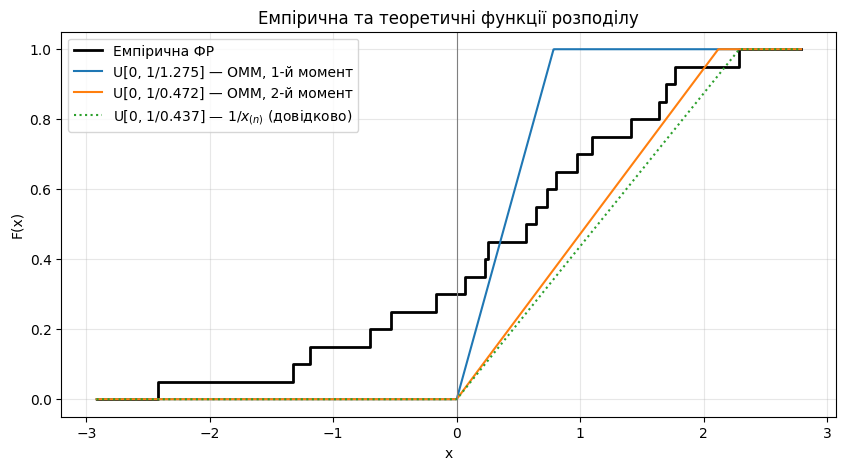

In [11]:
xs = np.linspace(X.min() - 0.5, max(X.max(), 1 / th_m1) + 0.5, 1000)
Xs = np.sort(X)
plt.figure(figsize=(10, 5))
plt.step(np.r_[xs[0], Xs, xs[-1]], np.r_[0, np.arange(1, n + 1) / n, 1], where='post',
         color='k', lw=2, label='Емпірична ФР')
for th, name, ls in [(th_m1, 'ОММ, 1-й момент', '-'), (th_m2, 'ОММ, 2-й момент', '-'),
                     (th_formal, r'$1/x_{(n)}$ (довідково)', ':')]:
    plt.plot(xs, stats.uniform(0, 1 / th).cdf(xs), ls=ls, label=f'U[0, 1/{th:.3f}] — {name}')
plt.axvline(0, color='gray', lw=.8)
plt.title('Емпірична та теоретичні функції розподілу')
plt.xlabel('x'); plt.ylabel('F(x)'); plt.grid(alpha=.3); plt.legend(); plt.show()

### Перевірка відповідності: критерій Колмогорова–Смирнова + моделювання
Параметр оцінено за тією ж вибіркою, тому табличні p-значення KS некоректні (тест стає надто консервативним). Тому p-значення для ОММ додатково рахуємо параметричним бутстрепом: генеруємо вибірки з $U[0,1/\hat\theta]$, заново оцінюємо $\theta$ і рахуємо статистику KS.

In [12]:
for th, name in [(th_m1, 'ОММ, 1-й момент'), (th_m2, 'ОММ, 2-й момент')]:
    r = stats.kstest(X, stats.uniform(0, 1 / th).cdf)
    print(f'{name:<16}: D = {r.statistic:.4f}, p-value = {r.pvalue:.2e}')

D_obs = stats.kstest(X, stats.uniform(0, 1 / th_m1).cdf).statistic
B = 5000
D_boot = np.empty(B)
for b in range(B):
    xb = rng.uniform(0, 1 / th_m1, size=n)
    D_boot[b] = stats.kstest(xb, stats.uniform(0, 1 / est_mm(xb)).cdf).statistic
p_boot = np.mean(D_boot >= D_obs)
p_str = f'< 1/B = {1 / B:.4f}' if p_boot == 0 else f'= {p_boot:.4f}'
print(f'\nБутстреп (ОММ, 1-й момент): D_obs = {D_obs:.4f}, p-value {p_str}')

ОММ, 1-й момент : D = 0.4000, p-value = 2.12e-03
ОММ, 2-й момент : D = 0.3292, p-value = 1.97e-02

Бутстреп (ОММ, 1-й момент): D_obs = 0.4000, p-value < 1/B = 0.0002


### Яка модель підходить краще?
Вибірка має значення по обидва боки від нуля й розташована приблизно симетрично навколо середнього, тому порівняємо Q-Q графіки для нормального та рівномірного розподілів.

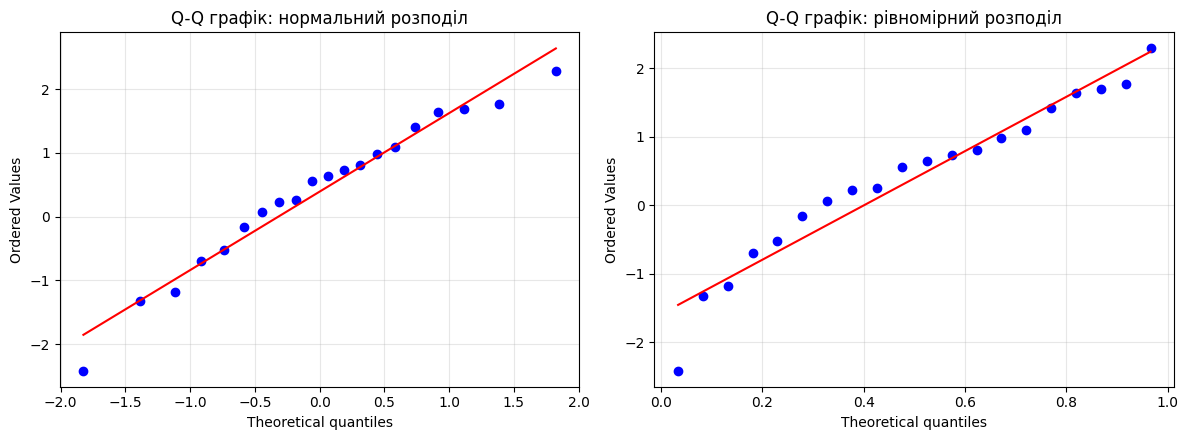

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
stats.probplot(X, dist='norm', plot=axes[0])
axes[0].set_title('Q-Q графік: нормальний розподіл')
stats.probplot(X, dist=stats.uniform, plot=axes[1])
axes[1].set_title('Q-Q графік: рівномірний розподіл')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Висновок
Оцінений розподіл $U[0, 1/\hat\theta]$ **не відповідає** вибірці:
- 6 з 20 спостережень від’ємні, а носій моделі — $[0, 1/\theta]$. Через це $L(\theta)\equiv 0$, і ОМВ та третя оцінка просто не існують; обчислити можна лише ОММ.
- Дві ОММ (за першим і другим моментами) суттєво розходяться, хоча за правильної моделі обидві прямували б до одного $\theta$ — ознака хибної моделі.
- Емпірична ФР досягає ≈0.3 вже в нулі, де теоретична дорівнює 0; KS і бутстреп-тест відхиляють рівномірність на рівні 0.05.
- На Q-Q графіку точки лягають майже на пряму для нормального розподілу і помітно відхиляються для рівномірного. Отже, вибірка, найімовірніше, з нормального розподілу, і припущення варіанта 3 для неї хибне.